# Microduck — Phase 0: setup and reproduction

Phase 0 of the work plan (`docs/Piano_lavoro_tesi_Preda.md`, section 5), in one notebook:

| Step of the plan | Section here | Product |
|---|---|---|
| 1. Install microduck_rl | 2 | working stack on Colab (T4) |
| 2. Run `alpha_walking` and `rough-walk-g` on flat and rough ground; reproduce the comparison of the [`rough-walk-g` card](https://huggingface.co/RemiFabre/microduck-rough-walk-g): falls on 110 rollouts and mean motor power | 6-9 | `battery_results.json`, comparison table |
| 3. Convert `alpha_walking` from ONNX to PyTorch and check that the outputs match | 10 | TorchScript policies + `torch_check.json` |
| 4. Short training run: cost of a specialist | 11 | `training_timing.json` (seconds per PPO iteration on this GPU) |
| Phase product: reproducible scripts and a table with falls, power and times | 12 | `fase0_summary.json` / `.md` |

**All the parameters are in the next cell** (section 0); the other cells only read them. Run the cells in order; sections 9-12 can be re-run on their own after a run, without simulating again.

**What is reproduced, and what is reconstructed.** The card numbers come from the eval field of the cards' `manifest.json`:

> *CPU MuJoCo with the BAM XL330 servo model; 10 s rollouts at 0.3 m/s, 5 random headings per terrain* — battery *flat, 0-1.5 cm grids, 1-3 cm stairs, ±0.2-2.5 cm rubble, 3-9° slopes* — falls *`alpha_walking` 32/110, `rough-walk-e` 14/110, `rough-walk-g` 12/110* — motor power on flat *1.03 / 1.02 / 1.21 W*

The script that produced them is not public (it lives in the author's `notes/tools/`, cited in the code). Taken as published: simulator (CPU MuJoCo), servo model (BAM XL330), rollout length, speed command, headings per terrain, terrain families and ranges, 110 rollouts. **Reconstructed**, and editable in the parameter cell: how the 22 terrains split the ranges, the shapes of the obstacles (taken from the hostile-terrain training menu, `hostile_terrains.py` @ `6cd45fc`), the servo settings (gain, voltage, current limit), the fall test (trunk tilt over 70°, as the training termination) and the power formula (mechanical, Σ|torque × joint speed|, as section 4.8 of the plan). The **criterion of the plan** is that the *gap* between the two policies is reproduced, not the exact counts.

Results go to `MyDrive/microduck_thesis/fase0/<RUN_NAME>/`.

**Before you start:** *Runtime → Change runtime type → T4 GPU* (the battery runs on the CPU; the GPU is needed for section 11).

## 0. Parameters

The only cell to edit. Re-run it after every change, then the sections you need.

In [1]:
# ============================== PHASE 0 PARAMETERS ==============================
# ---- code ----
REPO_URL = "https://github.com/pollen-robotics/microduck_rl"
REPO_REF = "6cd45fc"   # commit on branch hostile-terrain that rough-walk-g/e were trained with (card provenance)
REPO_DIR = "/content/microduck_rl"

# ---- results ----
DRIVE_DIR = "/content/drive/MyDrive/microduck_thesis/fase0"
RUN_NAME = "battery_v1"   # results folder: change it to keep an older run
FORCE_RERUN = False       # False: sections 7-11 skip what is already saved in the run folder

# ---- policies: Hugging Face (repo, file) or a path ----
POLICIES = {
    "alpha_walking": ("pollen-robotics/microduck-policies", "alpha_walking.onnx"),
    "rough_walk_g": ("RemiFabre/microduck-rough-walk-g", "policy.onnx"),
    # "rough_walk_e": ("RemiFabre/microduck-rough-walk-e", "policy.onnx"),   # alpha fine-tuned 800 it
}
# Card values (manifest.json "eval"), only for the comparison table
CARD = {
    "alpha_walking": {"falls": 32, "rollouts": 110, "flat_power_w": 1.03, "flat_speed_m_s": None},
    "rough_walk_g": {"falls": 12, "rollouts": 110, "flat_power_w": 1.21, "flat_speed_m_s": 0.11},
    "rough_walk_e": {"falls": 14, "rollouts": 110, "flat_power_w": 1.02, "flat_speed_m_s": 0.12},
}

# ---- battery protocol (cards: 10 s rollouts at 0.3 m/s, 5 random headings per terrain) ----
EPISODE_S = 10.0
COMMAND_VX_M_S = 0.3          # constant forward command, no turning command, no heading hold
HEADINGS_PER_TERRAIN = 5      # random headings, the same for every policy (paired comparison)
SEED = 0
# 22 terrains x 5 headings = 110 rollouts. The split inside each range is reconstructed (not published).
#   grid: blocks 45 cm wide, heights uniform in +-h      stairs: pyramid, 12 cm treads, start on the top
#   rubble: bumps every 8 cm, heights uniform in +-h     slope: training pyramid (mjlab), start on the top
BATTERY = (
    [{"name": "flat", "kind": "flat"}]
    + [{"name": f"grid_{h}cm", "kind": "grid", "height_cm": h} for h in (0.3, 0.6, 0.9, 1.2, 1.5)]
    + [{"name": f"stairs_{h}cm", "kind": "stairs", "height_cm": h} for h in (1.0, 1.5, 2.0, 2.5, 3.0)]
    + [{"name": f"rubble_{h}cm", "kind": "rubble", "height_cm": h} for h in (0.2, 0.75, 1.3, 1.9, 2.5)]
    + [{"name": f"slope_{d}deg", "kind": "slope", "deg": d} for d in (3.0, 4.2, 5.4, 6.6, 7.8, 9.0)]
)
PATCH_SIZE_M = 4.0            # terrain patch (as the hostile-terrain training); flat border all around
BORDER_WIDTH_M = 4.0

# ---- simulation (as scripts/infer_policy.py and scripts/testbench_sim2real.py) ----
SCENE_XML = "scene.xml"       # robot_allcollisions.xml + floor (the floor is replaced by the terrain)
PHYSICS_DT_S = 0.005          # 200 Hz physics
DECIMATION = 4                # policy at 50 Hz
SPAWN_HEIGHT_M = 0.125        # trunk height above the highest ground point under the robot
ACTION_SCALE = 1.0
ACTION_DELAY_STEPS = 0        # control steps of delay: an int, or [min, max] drawn per rollout
FALL_TILT_DEG = 70.0          # fall = trunk tilt from vertical above this (training termination "fell_over")
WARMUP_S = 1.0                # power, speed and yaw rate are averaged after this time
ACTUATOR = {
    "model": "bam",           # "bam": bam's MujocoController, XL330 m6 (voltage control + friction model)
                              # "position": XML position actuators + current limit, as infer_policy.py
    "kp": 200.0,              # firmware gain (microduck training value; bam's XL330 default is 400)
    "vin": 7.4,               # battery voltage [V] (training range 6.5-8.2)
    "max_current_a": 1.75,    # XL330 firmware current limit [A]
}

# ---- videos (one per selected rollout; [] = every terrain) ----
VIDEO = {"enabled": True, "headings": [0],
         "terrains": ["flat", "grid_1.2cm", "stairs_2.0cm", "rubble_1.9cm", "slope_9.0deg"],
         "every_n_steps": 2, "width": 640, "height": 480}

# ---- ONNX -> PyTorch check (plan section 4.5) ----
TORCH_CHECK = {"n_random": 10000, "n_real_max": 20000, "tolerance": 1e-5}

# ---- training cost (plan, phase 0 step 4) ----
TRAIN_TASK = "Mjlab-Hostile-FinetuneFeetProgress-MicroDuck"   # env of rough-walk-e (alpha fine-tuned on rough ground)
TRAIN_NUM_ENVS = 4096         # as in training; lower it if the GPU runs out of memory
TRAIN_ITERATIONS = 20         # PPO iterations to time
TRAIN_SKIP_FIRST = 3          # first iterations excluded from the average (compilation, warm-up)
FINETUNE_ITERATIONS_REF = 800 # iterations of the rough-walk-e fine-tune, to estimate the cost of a specialist
TRAIN_EXTRA_ARGS = []         # e.g. ["--agent.resume", "True", "--agent.load-checkpoint", "model_9999.pt"]
# ================================================================================

import os
RUN_DIR = os.path.join(DRIVE_DIR, RUN_NAME)
ROBOT_DIR = os.path.join(REPO_DIR, "src/mjlab_microduck/robot/microduck")
print(f"{len(BATTERY)} terrains x {HEADINGS_PER_TERRAIN} headings = {len(BATTERY) * HEADINGS_PER_TERRAIN} rollouts "
      f"per policy | policies: {', '.join(POLICIES)} | results: {RUN_DIR}")

22 terrains x 5 headings = 110 rollouts per policy | policies: alpha_walking, rough_walk_g | results: /content/drive/MyDrive/microduck_thesis/fase0/battery_v1


## 1. GPU check

In [ ]:
!nvidia-smi

## 2. Installation (step 1)

Clones microduck_rl at `REPO_REF` and installs the versions fixed in its `uv.lock` (mjlab 1.3.0, MuJoCo 3.10.0, torch 2.9.1, bam). A few minutes the first time.

In [2]:
import os, subprocess

!curl -LsSf https://astral.sh/uv/install.sh | sh
os.environ["PATH"] = "/root/.local/bin:" + os.environ["PATH"]
os.environ["UV_HTTP_TIMEOUT"] = "600"   # avoids timeouts on the large CUDA packages

if not os.path.exists(REPO_DIR):
    !git clone {REPO_URL} {REPO_DIR}
%cd {REPO_DIR}
!git fetch --all --quiet
!git checkout --quiet {REPO_REF}
print("microduck_rl at", subprocess.check_output(["git", "log", "-1", "--format=%h %ad %s", "--date=short"], text=True))
!uv sync
!uv run python -c "import torch, mujoco, mjlab, bam; print('CUDA:', torch.cuda.is_available(), '| torch', torch.__version__, '| mujoco', mujoco.__version__)"

downloading uv 0.13.1 x86_64-unknown-linux-gnu
installing to /usr/local/bin
  uv
  uvx
everything's installed!
Cloning into '/content/microduck_rl'...
remote: Enumerating objects: 16426, done.
remote: Counting objects: 100% (3138/3138), done.
remote: Compressing objects: 100% (392/392), done.
remote: Total 16426 (delta 2932), reused 2746 (delta 2746), pack-reused 13288 (from 2)
Receiving objects: 100% (16426/16426), 56.27 MiB | 19.30 MiB/s, done.
Resolving deltas: 100% (10482/10482), done.
/content/microduck_rl
microduck_rl at 6cd45fc7 2026-08-30 hostile terrain: anti-circling (run A hack: circles on the spawn platform track body-frame speed) — promotion needs real displacement, tighter yaw tracking std; variants FinetuneFeetProgress / ScratchFeetProgress

Using CPython 3.12.3 interpreter at: /usr/bin/python3.12
Creating virtual environment at: .venv
Resolved 154 packages in 1ms
Prepared 142 packages in 1m 19s
Installed 142 packages in 1.11s
 + absl-py==2.3.1
 + annotated-doc==0.0.4
 +

## 3. Offscreen rendering (videos and terrain preview)

Colab has no display: MuJoCo renders through EGL on the GPU. This cell registers the NVIDIA EGL driver if it is missing and selects EGL for the scripts.

In [3]:
NVIDIA_ICD_CONFIG_PATH = "/usr/share/glvnd/egl_vendor.d/10_nvidia.json"
if not os.path.exists(NVIDIA_ICD_CONFIG_PATH):
    os.makedirs(os.path.dirname(NVIDIA_ICD_CONFIG_PATH), exist_ok=True)
    with open(NVIDIA_ICD_CONFIG_PATH, "w") as f:
        f.write('{"file_format_version": "1.0.0", "ICD": {"library_path": "libEGL_nvidia.so.0"}}\n')
os.environ["MUJOCO_GL"] = "egl"
os.environ["PYOPENGL_PLATFORM"] = "egl"

## 4. Google Drive

In [7]:
from google.colab import drive
drive.mount("/content/drive")
os.makedirs(RUN_DIR, exist_ok=True)
print("results folder:", RUN_DIR)

Mounted at /content/drive
results folder: /content/drive/MyDrive/microduck_thesis/fase0/battery_v1


## 5. Policies

Downloads every policy of `POLICIES` (public Hugging Face repos). A local or Drive file is used as it is.

In [4]:
from huggingface_hub import hf_hub_download

POLICY_PATHS = {}
for name, source in POLICIES.items():
    if isinstance(source, str):
        POLICY_PATHS[name] = source
    else:
        repo, filename = source
        POLICY_PATHS[name] = hf_hub_download(repo, filename, local_dir=f"/content/policies/{name}")
    print(f"{name:15s} -> {POLICY_PATHS[name]} | found: {os.path.exists(POLICY_PATHS[name])}")

alpha_walking.onnx: reconstructing file:   0%|          |  0.00B /  794kB            

alpha_walking.onnx: downloading bytes:           |  0.00B            

alpha_walking   -> /content/policies/alpha_walking/alpha_walking.onnx | found: True


policy.onnx: reconstructing file:   0%|          |  0.00B /  794kB            

policy.onnx: downloading bytes:           |  0.00B            

rough_walk_g    -> /content/policies/rough_walk_g/policy.onnx | found: True


## 6. The battery script

`fase0_battery.py` runs the rollouts on the CPU, one policy and one terrain at a time (about 2-3 minutes for 2 × 110 rollouts). How each part is built:

| Part | Implementation | Source |
|---|---|---|
| Robot | `scene.xml` (`robot_allcollisions.xml`), floor replaced by the terrain | `scripts/infer_policy.py` |
| Motors | bam `MujocoController`, XL330 `m6` model: torque from voltage control with the firmware gain and current limit, load-dependent friction written on the joints at every physics step | `scripts/testbench_sim2real.py` |
| Observations (61) | gyro (3), projected gravity (3), joint positions − default pose (14), joint velocities (14), last action (14), command (13: vx = 0.3, everything else 0) | `infer_policy.py --new-cmd-obs` |
| Control | 50 Hz, 4 physics steps of 5 ms per action, target = default pose + action | `infer_policy.py` |
| Terrain | one mjlab sub-terrain per battery entry, fixed size, 4 m patch with a flat border; same sample for every policy | `hostile_terrains.py` @ `6cd45fc` |
| Start | centre of the patch (on the top platform for stairs and slopes), trunk 12.5 cm above the highest ground point under the robot, random heading | |
| Fall | trunk tilt from vertical > 70° | mjlab `fell_over` |
| Power | mechanical, mean over the rollout of Σ\|torque × joint speed\| (14 motors), after 1 s | plan, section 4.8 |
| Speed | mean trunk velocity along the robot's own forward axis (the speed along the path, also when the robot turns) | |

Per rollout it also records the yaw rate (drift), the distance travelled and whether the robot left the patch (`max_dist_from_centre_m`). It saves the observations of the first heading of each terrain (`obs_samples_<policy>.npz`), used in section 10.

In [12]:
%%writefile fase0_battery.py
"""Phase 0 (work plan, section 5): the rough-ground battery of the rough-walk-g / rough-walk-e cards.

Protocol, from the eval field of the cards' manifest.json:
    "CPU MuJoCo with the BAM XL330 servo model; 10 s rollouts at 0.3 m/s, 5 random headings per terrain"
    battery: flat, 0-1.5 cm grids, 1-3 cm stairs, +/-0.2-2.5 cm rubble, 3-9 deg slopes; 110 rollouts
    (alpha_walking 32/110 falls, rough-walk-e 14/110, rough-walk-g 12/110)
The script that produced those numbers is not public: the list of the 22 terrains, the fall test
and the power formula are reconstructed here and are all set in the parameter cell of the notebook.

Simulation (no GPU, no mjlab environment):
  * robot: the MuJoCo scene of scripts/infer_policy.py (robot_allcollisions.xml), 5 ms physics step,
    policy at 50 Hz (4 physics steps per action);
  * motors: bam's MujocoController with the XL330 "m6" model (voltage control, firmware current limit,
    load-dependent friction), as in scripts/testbench_sim2real.py; or the XML position actuators with
    the current limit of infer_policy.py (ACTUATOR_MODEL = "position");
  * observations: the 61 numbers of infer_policy.py --new-cmd-obs: gyro, projected gravity, joint
    positions relative to the default pose, joint velocities, last action, 13-D command;
  * terrain: one mjlab sub-terrain (the classes of the training generator) per battery entry.

Usage:
    uv run --with "imageio[ffmpeg]" python fase0_battery.py fase0_battery.json
    uv run --with "imageio[ffmpeg]" python fase0_battery.py fase0_battery.json --preview
"""
import csv
import json
import math
import os
import sys
import time

import mujoco
import numpy as np
import onnxruntime as ort
from mjlab.terrains.heightfield_terrains import HfPyramidSlopedTerrainCfg, HfRandomUniformTerrainCfg
from mjlab.terrains.primitive_terrains import (BoxFlatTerrainCfg, BoxPyramidStairsTerrainCfg,
                                               BoxRandomGridTerrainCfg)
from mjlab.terrains.terrain_generator import TerrainGenerator, TerrainGeneratorCfg

# Default pose of scripts/infer_policy.py (STAND keyframe of scene.xml), in actuator order:
# actions are offsets from it, joint observations are relative to it.
DEFAULT_POSE = np.array([
    0.0, -0.0873, -0.4579, -0.0049, 0.4530,    # left leg: hip yaw, hip roll, hip pitch, knee, ankle
    0.3491, 0.3491, 0.0, 0.0,                  # neck pitch, head pitch, head yaw, head roll
    0.0, 0.0873, 0.4579, 0.0049, -0.4530,      # right leg
], dtype=np.float32)


# ---------------------------------------------------------------------------
# log
# ---------------------------------------------------------------------------

def log(msg):
    """Print immediately: through a pipe (| grep in the notebook) Python would buffer the output."""
    print(msg, flush=True)


def describe(t):
    """Short description of a battery entry, e.g. 'stairs, 2.0 cm' or 'slope, 9.0 deg'."""
    if "height_cm" in t:
        return f"{t['kind']}, {t['height_cm']} cm"
    if "deg" in t:
        return f"{t['kind']}, {t['deg']} deg"
    return t["kind"]


# ---------------------------------------------------------------------------
# Terrain
# ---------------------------------------------------------------------------
def make_subterrain(t):
    """One battery entry -> mjlab sub-terrain with FIXED obstacle size (difficulty plays no role).
    Shapes and spacings are those of the hostile-terrain training menu (hostile_terrains.py @ 6cd45fc)."""
    kind = t["kind"]
    if kind == "flat":
        return BoxFlatTerrainCfg(proportion=1.0)
    if kind == "grid":   # blocks 45 cm wide, heights uniform in +-h around the platform level
        h = float(t["height_cm"]) / 100
        return BoxRandomGridTerrainCfg(proportion=1.0, grid_width=0.45, grid_height_range=(h, h),
                                       platform_width=1.0, border_width=0.25)
    if kind == "stairs":  # pyramid stairs, 12 cm treads, robot starts on the top platform
        h = float(t["height_cm"]) / 100
        return BoxPyramidStairsTerrainCfg(proportion=1.0, step_height_range=(h, h), step_width=0.12,
                                          platform_width=0.8, border_width=0.2)
    if kind == "rubble":  # bumps every 8 cm, heights uniform in +-h
        h = float(t["height_cm"]) / 100
        return HfRandomUniformTerrainCfg(proportion=1.0, noise_range=(-h, h), noise_step=0.002,
                                         downsampled_scale=0.08, horizontal_scale=0.04, vertical_scale=0.001,
                                         border_width=0.2)
    if kind == "slope":   # pyramid of the training generator, robot starts on the top platform
        s = math.tan(math.radians(float(t["deg"])))
        return HfPyramidSlopedTerrainCfg(proportion=1.0, slope_range=(s, s), platform_width=0.8,
                                         horizontal_scale=0.1, vertical_scale=0.001)
    raise SystemExit(f"unknown terrain kind {kind!r} (flat, grid, stairs, rubble, slope)")


def build_model(conf, terrain, terrain_seed):
    """Robot scene + one terrain patch (centred on the world origin) + flat border."""
    spec = mujoco.MjSpec.from_file(os.path.join(conf["robot_dir"], conf["scene_xml"]))
    floor = spec.geom("floor")
    if floor is not None:
        spec.delete(floor)  # the generated terrain (patch + flat border at z = 0) replaces the plane
    gen = TerrainGenerator(TerrainGeneratorCfg(
        size=(conf["patch_size_m"], conf["patch_size_m"]), border_width=conf["border_width_m"],
        num_rows=1, num_cols=1, curriculum=False, difficulty_range=(1.0, 1.0),
        sub_terrains={terrain["name"]: make_subterrain(terrain)}, add_lights=False, seed=terrain_seed))
    gen.compile(spec)

    act = conf["actuator"]
    kt = R = None
    if act["model"] == "bam":
        # As scripts/testbench_sim2real.py: torque motors driven by bam's MujocoController, with the
        # voltage-bounded force range; joint friction and damping are set by bam at every step.
        from bam.model import load_model
        bam_model = load_model(motor_name="xl330", model="m6")
        kt, R = bam_model.kt.value, bam_model.R.value
        for a in spec.actuators:
            a.set_to_motor()
            a.forcelimited = False
            a.forcerange = (-act["vin"] * kt / R, act["vin"] * kt / R)
            a.gear = [1.0, 0, 0, 0, 0, 0]
        for j in spec.joints:
            if j.type == mujoco.mjtJoint.mjJNT_HINGE:
                j.damping = np.zeros_like(j.damping) if np.ndim(j.damping) else 0.0  # array in newer MuJoCo
                j.frictionloss = 0.0
    model = spec.compile()
    model.opt.timestep = conf["physics_dt_s"]
    if act["model"] == "position" and act.get("max_current_a"):
        # As scripts/infer_policy.py: XML position actuators, force clipped at kt x firmware current limit
        from bam.model import load_model
        kt = load_model(motor_name="xl330", model="m6").kt.value
        model.actuator_forcerange[:] = [-kt * act["max_current_a"], kt * act["max_current_a"]]
        model.actuator_forcelimited[:] = 1
    return model, gen.terrain_origins[0, 0].copy()


def ground_height(model, data, x, y, radius=0.1):
    """Highest terrain point within `radius` of (x, y), by vertical rays (robot moved out of the way)."""
    best = -np.inf
    geomid = np.zeros(1, dtype=np.int32)
    for dx in np.linspace(-radius, radius, 5):
        for dy in np.linspace(-radius, radius, 5):
            d = mujoco.mj_ray(model, data, np.array([x + dx, y + dy, 20.0]), np.array([0.0, 0.0, -1.0]),
                              None, 1, -1, geomid)
            if d >= 0:
                best = max(best, 20.0 - d)
    return float(best)


# ---------------------------------------------------------------------------
# Robot and policy
# ---------------------------------------------------------------------------
class Robot:
    def __init__(self, model, conf):
        self.model, self.conf = model, conf
        self.data = mujoco.MjData(model)
        self.trunk = model.body("trunk_base").id
        self.free_qpos = model.jnt_qposadr[model.joint("trunk_base_freejoint").id]
        self.free_dof = model.jnt_dofadr[model.joint("trunk_base_freejoint").id]
        self.gyro_adr = model.sensor_adr[model.sensor("imu_ang_vel").id]
        jids = model.actuator_trnid[:, 0]
        self.qpos_idx = model.jnt_qposadr[jids]
        self.dof_idx = model.jnt_dofadr[jids]
        self.act_names = [model.actuator(i).name for i in range(model.nu)]
        if model.nu != len(DEFAULT_POSE):
            raise SystemExit(f"expected {len(DEFAULT_POSE)} actuators, found {model.nu}")
        self.ctrl = None
        act = conf["actuator"]
        if act["model"] == "bam":
            from bam.model import load_model
            from bam.mujoco import MujocoController
            bam_model = load_model(motor_name="xl330", model="m6")
            bam_model.actuator.kp = act["kp"]
            bam_model.actuator.vin = act["vin"]
            if hasattr(bam_model.actuator, "max_current"):
                bam_model.actuator.max_current = act.get("max_current_a")
            self.ctrl = MujocoController(bam_model, self.act_names, model, self.data)
        # bam rewrites dof friction and damping at every step: keep the initial values for the resets
        self.frictionloss0 = model.dof_frictionloss.copy()
        self.damping0 = model.dof_damping.copy()

    def reset(self, x, y, z, yaw):
        m, d = self.model, self.data
        m.dof_frictionloss[:] = self.frictionloss0
        m.dof_damping[:] = self.damping0
        mujoco.mj_resetData(m, d)
        a = self.free_qpos
        d.qpos[a:a + 3] = [x, y, z]
        d.qpos[a + 3:a + 7] = [math.cos(yaw / 2), 0.0, 0.0, math.sin(yaw / 2)]
        d.qpos[self.qpos_idx] = DEFAULT_POSE
        if self.ctrl is None:
            d.ctrl[:] = DEFAULT_POSE
        mujoco.mj_forward(m, d)
        if self.ctrl is not None:
            self.ctrl.last_ts = d.time
            self.ctrl.reset(d.qpos)

    def to_body(self, vec):
        """World vector rotated into the trunk frame."""
        q = self.data.xquat[self.trunk]
        w, v = q[0], q[1:4]
        t = np.cross(v, vec) * 2
        return vec - w * t + np.cross(v, t)

    def gravity_b(self):
        return self.to_body(np.array([0.0, 0.0, -1.0]))

    def forward_velocity(self):
        """Trunk velocity along the robot's own forward axis [m/s] (speed along a curved path too)."""
        return float(self.to_body(self.data.qvel[self.free_dof:self.free_dof + 3])[0])

    def yaw_rate(self):
        return float(self.data.sensordata[self.gyro_adr + 2])

    def observation(self, last_action, command):
        d = self.data
        return np.concatenate([
            d.sensordata[self.gyro_adr:self.gyro_adr + 3],
            self.gravity_b(),
            d.qpos[self.qpos_idx] - DEFAULT_POSE,
            d.qvel[self.dof_idx],
            last_action,
            command,
        ]).astype(np.float32)

    def step(self, target):
        """One physics step towards the joint targets; returns the mechanical motor power [W]."""
        m, d = self.model, self.data
        if self.ctrl is not None:
            self.ctrl.q_target[:] = target
            self.ctrl.update()
        else:
            d.ctrl[:] = target
        mujoco.mj_step(m, d)
        return float(np.abs(d.actuator_force * d.qvel[self.dof_idx]).sum())


class Policy:
    def __init__(self, path):
        self.sess = ort.InferenceSession(path, providers=["CPUExecutionProvider"])
        self.inp = self.sess.get_inputs()[0].name
        n = self.sess.get_inputs()[0].shape[-1]
        if n != 61:
            raise SystemExit(f"{path}: the policy takes {n} observations, this battery builds the 61-D layout")

    def __call__(self, obs):
        return self.sess.run(None, {self.inp: obs[None]})[0][0].astype(np.float32)


# ---------------------------------------------------------------------------
# One rollout
# ---------------------------------------------------------------------------
def rollout(robot, policy, conf, origin, yaw, rng, video=None, obs_log=None, tag=""):
    m, d = robot.model, robot.data
    d.qpos[robot.free_qpos + 2] = 100.0          # robot out of the way of the ground rays
    mujoco.mj_forward(m, d)
    z0 = ground_height(m, d, origin[0], origin[1]) + conf["spawn_height_m"]
    robot.reset(origin[0], origin[1], z0, yaw)

    command = np.zeros(13, dtype=np.float32)
    command[0] = conf["command_vx_m_s"]
    last_action = np.zeros(14, dtype=np.float32)
    lag = conf["action_delay_steps"]
    lag = int(rng.integers(lag[0], lag[1] + 1)) if isinstance(lag, list) else int(lag)
    queue = [DEFAULT_POSE.copy()] * (lag + 1)
    decimation = conf["decimation"]
    control_dt = decimation * conf["physics_dt_s"]
    n_steps = int(round(conf["episode_s"] / control_dt))
    log_every = int(round(conf.get("log_every_s", 2.0) / control_dt))   # 0 = no progress lines
    cos_fall = math.cos(math.radians(conf["fall_tilt_deg"]))
    start = d.qpos[robot.free_qpos:robot.free_qpos + 2].copy()
    heading = np.array([math.cos(yaw), math.sin(yaw)])
    power, vfwd, yaw_rate, max_tilt, outcome, step = [], [], [], 0.0, "completed", 0
    warmup = int(round(conf["warmup_s"] / control_dt))
    t_wall = time.time()

    for step in range(n_steps):
        obs = robot.observation(last_action, command)
        if obs_log is not None:
            obs_log.append(obs)
        action = policy(obs)
        last_action = action
        queue.append(DEFAULT_POSE + conf["action_scale"] * action)
        target = queue.pop(0)
        p = 0.0
        for _ in range(decimation):
            p += robot.step(target)
        if step >= warmup:  # skip the first instants after the spawn
            power.append(p / decimation)
            vfwd.append(robot.forward_velocity())
            yaw_rate.append(robot.yaw_rate())
        if video is not None:
            video.capture(d, step)
        if not np.all(np.isfinite(d.qpos)):
            outcome = "nan"
            break
        up = -robot.gravity_b()[2]               # cos of the trunk tilt from vertical
        tilt = math.degrees(math.acos(float(np.clip(up, -1.0, 1.0))))
        max_tilt = max(max_tilt, tilt)
        if up < cos_fall:
            outcome = "fell"
            break
        if log_every and (step + 1) % log_every == 0:
            pos = d.qpos[robot.free_qpos:robot.free_qpos + 2]
            log(f"      {tag} sim {(step + 1) * control_dt:5.1f}/{conf['episode_s']:.1f} s "
                f"(step {step + 1}/{n_steps}) | tilt {tilt:4.1f} deg | "
                f"{np.linalg.norm(pos - start):.2f} m from start | power {p / decimation:.2f} W")

    duration = (step + 1) * control_dt
    pos = d.qpos[robot.free_qpos:robot.free_qpos + 2]
    delta = pos - start
    log(f"      {tag} -> {outcome.upper()} at {duration:.2f} s simulated (step {step + 1}/{n_steps}), "
        f"max tilt {max_tilt:.1f} deg, {np.linalg.norm(delta):.2f} m from start, "
        f"wall time {time.time() - t_wall:.1f} s")
    return {
        "outcome": outcome,
        "duration_s": duration,
        "fall_time_s": duration if outcome == "fell" else None,
        "forward_m": float(delta @ heading),                       # along the initial heading
        "distance_m": float(np.linalg.norm(delta)),               # straight line, start to end
        "path_speed_m_s": float(np.mean(vfwd)) if vfwd else None,  # along the robot's own forward axis
        "mean_yaw_rate_rad_s": float(np.mean(yaw_rate)) if yaw_rate else None,  # + = turning left
        "max_dist_from_centre_m": float(np.linalg.norm(pos - origin[:2])),
        "mean_power_w": float(np.mean(power)) if power else None,
        "max_tilt_deg": max_tilt,
        "action_delay_steps": lag,
    }



class Video:
    def __init__(self, model, conf):
        self.renderer = mujoco.Renderer(model, conf["video"]["height"], conf["video"]["width"])
        self.cam = mujoco.MjvCamera()
        self.cam.type = mujoco.mjtCamera.mjCAMERA_TRACKING
        self.cam.trackbodyid = model.body("trunk_base").id
        self.cam.distance, self.cam.elevation, self.cam.azimuth = 0.9, -20.0, 135.0
        self.every = conf["video"]["every_n_steps"]
        self.frames = []

    def capture(self, data, step):
        if step % self.every == 0:
            self.renderer.update_scene(data, camera=self.cam)
            self.frames.append(self.renderer.render().copy())

    def save(self, path, fps):
        import imageio
        imageio.mimsave(path, self.frames, fps=fps)
        self.renderer.close()


def wilson_ci(k, n, z=1.96):
    """95% Wilson confidence interval of a proportion, in percent."""
    if n == 0:
        return None
    p = k / n
    den = 1 + z * z / n
    centre = (p + z * z / (2 * n)) / den
    half = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return [100.0 * max(0.0, centre - half), 100.0 * min(1.0, centre + half)]


# ---------------------------------------------------------------------------
# Main
# ---------------------------------------------------------------------------
def preview(conf):
    """One still per terrain with the robot at its spawn, to check the battery by eye."""
    import imageio
    tiles = []
    for i, t in enumerate(conf["battery"]):
        model, origin = build_model(conf, t, conf["seed"] + i)
        robot = Robot(model, conf)
        d = robot.data
        d.qpos[robot.free_qpos + 2] = 100.0
        mujoco.mj_forward(model, d)
        robot.reset(origin[0], origin[1], ground_height(model, d, origin[0], origin[1]) + conf["spawn_height_m"], 0.0)
        r = mujoco.Renderer(model, 240, 320)
        cam = mujoco.MjvCamera()
        cam.lookat[:] = [origin[0], origin[1], d.qpos[robot.free_qpos + 2] - 0.1]
        cam.distance, cam.elevation, cam.azimuth = 2.2, -30.0, 135.0
        r.update_scene(d, camera=cam)
        tiles.append((t["name"], r.render().copy()))
        r.close()
        print(f"[preview] {t['name']}: spawn z = {d.qpos[robot.free_qpos + 2]:.3f} m")
    cols = 4
    rows = [np.concatenate([im for _, im in tiles[i:i + cols]] + [np.zeros_like(tiles[0][1])] *
                           (cols - len(tiles[i:i + cols])), axis=1) for i in range(0, len(tiles), cols)]
    path = os.path.join(conf["out_dir"], "battery_preview.png")
    imageio.imwrite(path, np.concatenate(rows, axis=0))
    print("saved", path, "| order:", ", ".join(n for n, _ in tiles))


def main(conf):
    os.makedirs(conf["out_dir"], exist_ok=True)
    t0 = time.time()
    rng_head = np.random.default_rng(conf["seed"])
    # Same headings for every policy (paired comparison): drawn once per terrain
    headings = {t["name"]: rng_head.uniform(-math.pi, math.pi, conf["headings_per_terrain"]).tolist()
                for t in conf["battery"]}
    episodes = []
    video_dir = os.path.join(conf["out_dir"], "videos")
    vconf = conf["video"]
    n_terrains = len(conf["battery"])
    for p_idx, (pname, ppath) in enumerate(conf["policies"].items()):
        log(f"\n=== policy {p_idx + 1}/{len(conf['policies'])}: {pname} ({ppath}) ===")
        policy = Policy(ppath)
        obs_log = []
        for i, t in enumerate(conf["battery"]):
            log(f"[{pname}] terrain {i + 1}/{n_terrains}: {t['name']} ({describe(t)}) - building the scene")
            model, origin = build_model(conf, t, conf["seed"] + i)  # same terrain sample for every policy
            robot = Robot(model, conf)
            rng = np.random.default_rng(conf["seed"] + 1000 + i)
            for k, yaw in enumerate(headings[t["name"]]):
                log(f"  [{pname}] {t['name']} heading {k + 1}/{len(headings[t['name']])}: "
                    f"{math.degrees(yaw):+.0f} deg, {conf['episode_s']:.0f} s at {conf['command_vx_m_s']} m/s")
                video = None
                if vconf["enabled"] and k in vconf["headings"] and (not vconf["terrains"] or t["name"] in vconf["terrains"]):
                    try:
                        video = Video(model, conf)
                    except Exception as e:  # noqa: BLE001  rendering is optional: the numbers do not need it
                        log(f"[WARNING] videos disabled, the renderer could not start ({e}); is MUJOCO_GL=egl set?")
                        vconf["enabled"] = False
                ep = rollout(robot, policy, conf, origin, yaw, rng, video,
                             obs_log if k == 0 else None, tag=f"{t['name']} h{k + 1}")
                ep.update({"policy": pname, "terrain": t["name"], "kind": t["kind"], "heading_idx": k,
                           "heading_deg": math.degrees(yaw)})
                episodes.append(ep)
                if video is not None:
                    os.makedirs(video_dir, exist_ok=True)
                    fps = 1.0 / (conf["decimation"] * conf["physics_dt_s"] * vconf["every_n_steps"])
                    video.save(os.path.join(video_dir, f"{pname}__{t['name']}__h{k}.mp4"), fps)
                    log(f"      video saved: {pname}__{t['name']}__h{k}.mp4")
            fell = sum(e["outcome"] == "fell" for e in episodes if e["policy"] == pname and e["terrain"] == t["name"])
            log(f"[{pname}] {t['name']:16s} done: falls {fell}/{len(headings[t['name']])}  "
                f"(elapsed {time.time() - t0:.0f} s)")
        np.savez_compressed(os.path.join(conf["out_dir"], f"obs_samples_{pname}.npz"), obs=np.stack(obs_log))
        log(f"=== {pname}: saved obs_samples_{pname}.npz ===")


    # ---- summary ----
    summary = {}
    for pname in conf["policies"]:
        eps = [e for e in episodes if e["policy"] == pname]
        n, falls = len(eps), sum(e["outcome"] == "fell" for e in eps)
        flat = [e for e in eps if e["kind"] == "flat" and e["outcome"] == "completed"]
        by_kind = {}
        for e in eps:
            k = by_kind.setdefault(e["kind"], [0, 0])
            k[0] += e["outcome"] == "fell"
            k[1] += 1
        summary[pname] = {
            "rollouts": n, "falls": falls, "falls_ci95_pct": wilson_ci(falls, n),
            "nan": sum(e["outcome"] == "nan" for e in eps),
            "falls_by_kind": {k: f"{v[0]}/{v[1]}" for k, v in by_kind.items()},
            "flat_speed_m_s": float(np.mean([e["path_speed_m_s"] for e in flat])) if flat else None,
            "flat_power_w": float(np.mean([e["mean_power_w"] for e in flat])) if flat else None,
            "flat_yaw_rate_rad_s": float(np.mean([e["mean_yaw_rate_rad_s"] for e in flat])) if flat else None,
            "left_patch": sum(e["max_dist_from_centre_m"] > conf["patch_size_m"] / 2 for e in eps),
        }
    out = {"config": conf, "headings_deg": {k: [math.degrees(h) for h in v] for k, v in headings.items()},
           "summary": summary, "episodes": episodes, "runtime_s": time.time() - t0,
           "versions": {"mujoco": mujoco.__version__, "onnxruntime": ort.__version__}}
    with open(os.path.join(conf["out_dir"], "battery_results.json"), "w") as f:
        json.dump(out, f, indent=1)
    with open(os.path.join(conf["out_dir"], "battery_episodes.csv"), "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=list(episodes[0].keys()))
        w.writeheader()
        w.writerows(episodes)
    for pname, s in summary.items():
        fmt = lambda v, n=2: "-" if v is None else f"{v:.{n}f}"  # noqa: E731
        print(f"{pname}: falls {s['falls']}/{s['rollouts']} | flat: speed {fmt(s['flat_speed_m_s'])} m/s, "
              f"power {fmt(s['flat_power_w'])} W, yaw rate {fmt(s['flat_yaw_rate_rad_s'])} rad/s | "
              f"falls by kind {s['falls_by_kind']}")
    print(f"done in {time.time() - t0:.0f} s -> {conf['out_dir']}")


if __name__ == "__main__":
    with open(sys.argv[1]) as f:
        cfg = json.load(f)
    preview(cfg) if "--preview" in sys.argv else main(cfg)

Overwriting fase0_battery.py


## 7. Terrain preview

One still per terrain with the robot at its start, to check the battery by eye before running it (`battery_preview.png`, in the order of `BATTERY`, four per row).

[mdp] Patches 1-2 active: NaN-safe reward/advantage
[mdp] Patch 4 active: ONNX export filters passive_* joints
[preview] flat: spawn z = 0.125 m
[preview] grid_0.3cm: spawn z = 0.128 m
[preview] grid_0.6cm: spawn z = 0.131 m
[preview] grid_0.9cm: spawn z = 0.134 m
[preview] grid_1.2cm: spawn z = 0.137 m
[preview] grid_1.5cm: spawn z = 0.140 m
[preview] stairs_1.0cm: spawn z = 0.245 m
[preview] stairs_1.5cm: spawn z = 0.305 m
[preview] stairs_2.0cm: spawn z = 0.365 m
[preview] stairs_2.5cm: spawn z = 0.425 m
[preview] stairs_3.0cm: spawn z = 0.485 m
[preview] rubble_0.2cm: spawn z = 0.131 m
[preview] rubble_0.75cm: spawn z = 0.140 m
[preview] rubble_1.3cm: spawn z = 0.158 m
[preview] rubble_1.9cm: spawn z = 0.171 m
[preview] rubble_2.5cm: spawn z = 0.179 m
[preview] slope_3.0deg: spawn z = 0.192 m
[preview] slope_4.2deg: spawn z = 0.218 m
[preview] slope_5.4deg: spawn z = 0.246 m
[preview] slope_6.6deg: spawn z = 0.273 m
[preview] slope_7.8deg: spawn z = 0.300 m
[preview] slope_9.0deg: 

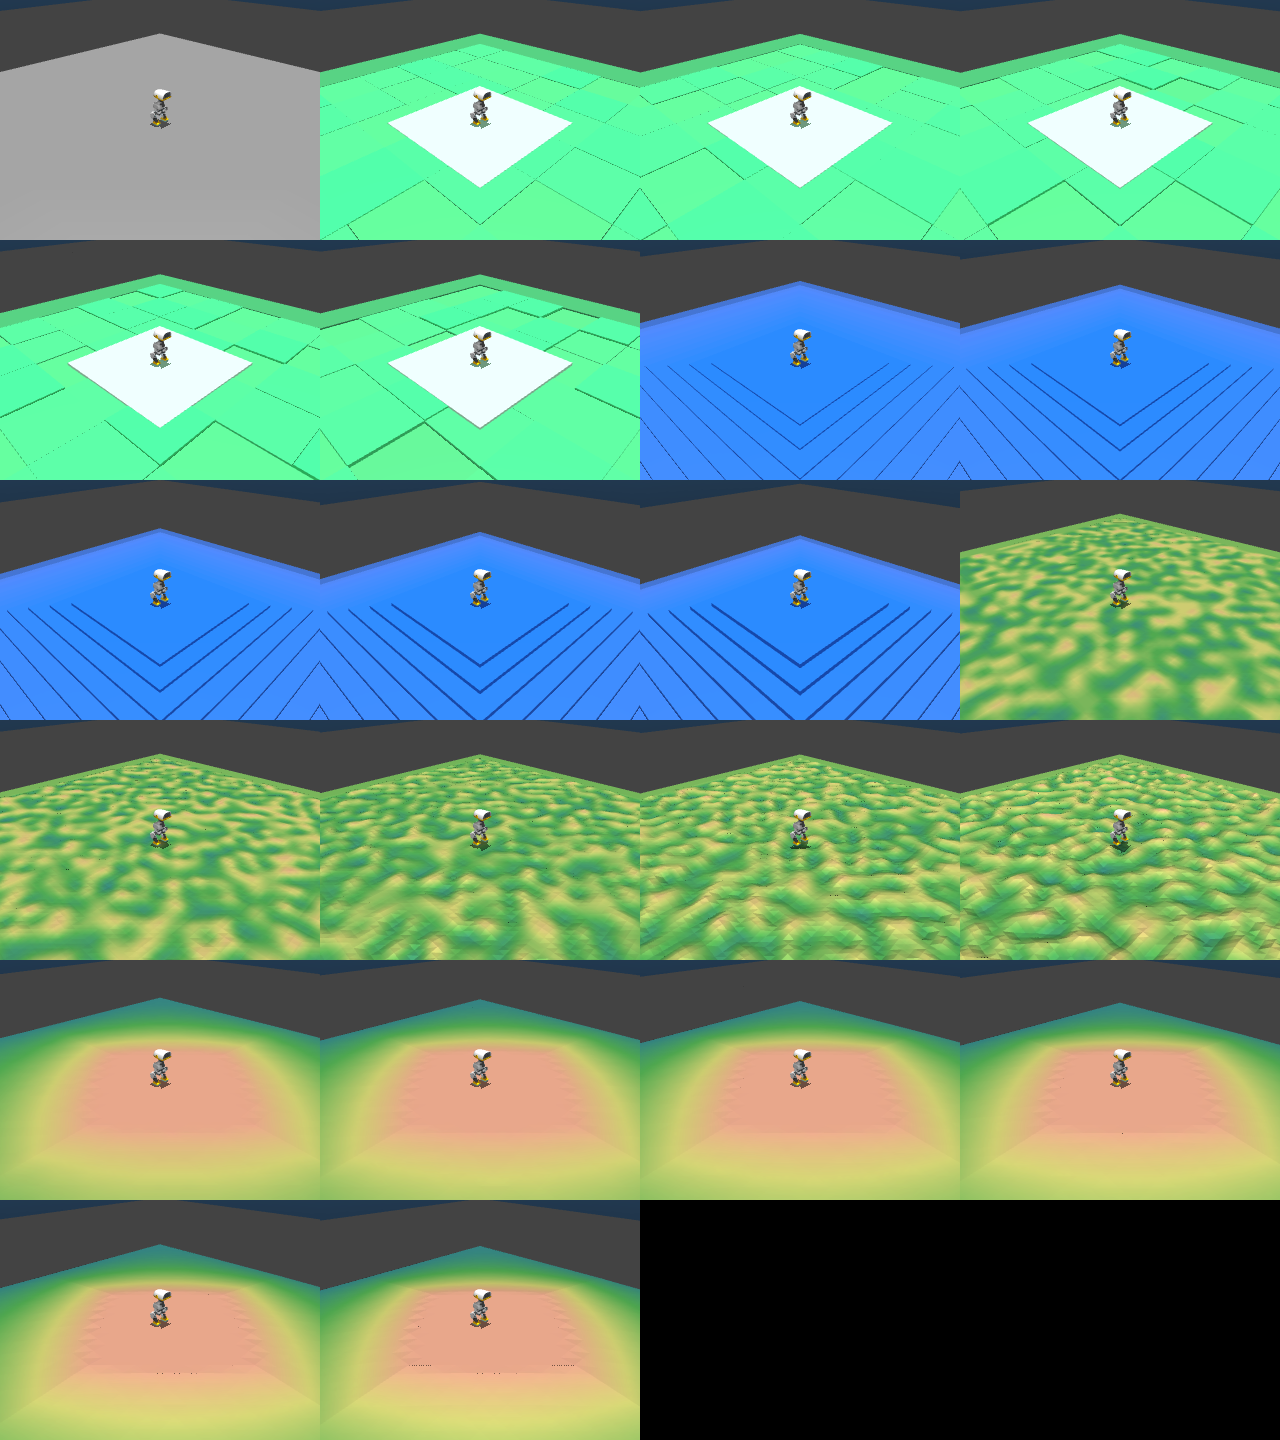

In [8]:
import json
from IPython.display import Image, display

def battery_config():
    return {
        "robot_dir": ROBOT_DIR, "scene_xml": SCENE_XML, "policies": POLICY_PATHS, "battery": BATTERY,
        "patch_size_m": PATCH_SIZE_M, "border_width_m": BORDER_WIDTH_M, "physics_dt_s": PHYSICS_DT_S,
        "decimation": DECIMATION, "episode_s": EPISODE_S, "command_vx_m_s": COMMAND_VX_M_S,
        "headings_per_terrain": HEADINGS_PER_TERRAIN, "seed": SEED, "warmup_s": WARMUP_S,
        "spawn_height_m": SPAWN_HEIGHT_M, "fall_tilt_deg": FALL_TILT_DEG, "action_scale": ACTION_SCALE,
        "action_delay_steps": ACTION_DELAY_STEPS, "actuator": ACTUATOR, "video": VIDEO, "out_dir": RUN_DIR,
    }

with open("fase0_battery.json", "w") as f:
    json.dump(battery_config(), f, indent=1)
!uv run --with "imageio[ffmpeg]" python fase0_battery.py fase0_battery.json --preview 2>&1 | grep -v "Terrain generation took"
display(Image(os.path.join(RUN_DIR, "battery_preview.png")))

## 8. Run the battery (step 2)

Skipped if `battery_results.json` is already in the run folder (set `FORCE_RERUN = True` or change `RUN_NAME` to run again).

In [13]:
with open("fase0_battery.json", "w") as f:
    json.dump(battery_config(), f, indent=1)
if os.path.exists(os.path.join(RUN_DIR, "battery_results.json")) and not FORCE_RERUN:
    print("battery already run in", RUN_DIR, "- set FORCE_RERUN = True to run it again")
else:
    !uv run --with "imageio[ffmpeg]" python fase0_battery.py fase0_battery.json 2>&1 | grep -v "Terrain generation took"

[mdp] Patches 1-2 active: NaN-safe reward/advantage
[mdp] Patch 4 active: ONNX export filters passive_* joints

=== policy 1/2: alpha_walking (/content/policies/alpha_walking/alpha_walking.onnx) ===
[alpha_walking] terrain 1/22: flat (flat) - building the scene
  [alpha_walking] flat heading 1/5: +49 deg, 10 s at 0.3 m/s
      flat h1 sim   2.0/10.0 s (step 100/500) | tilt  3.3 deg | 0.27 m from start | power 0.87 W
      flat h1 sim   4.0/10.0 s (step 200/500) | tilt  3.7 deg | 0.56 m from start | power 0.34 W
      flat h1 sim   6.0/10.0 s (step 300/500) | tilt  3.5 deg | 0.85 m from start | power 1.18 W
      flat h1 sim   8.0/10.0 s (step 400/500) | tilt  3.2 deg | 1.13 m from start | power 1.38 W
      flat h1 sim  10.0/10.0 s (step 500/500) | tilt  0.8 deg | 1.40 m from start | power 1.65 W
      flat h1 -> COMPLETED at 10.00 s simulated (step 500/500), max tilt 4.7 deg, 1.40 m from start, wall time 2.3 s
      video saved: alpha_walking__flat__h0.mp4
  [alpha_walking] flat headi

## 9. Results against the cards

- **falls**: rollouts ending with a fall, out of 110, with the 95% Wilson interval;
- **power**: mean mechanical motor power on flat ground; the cards do not say how they compute it, so compare the **ratio** between the policies (card: `rough-walk-g` +17% over `alpha_walking`) more than the watts;
- **speed**: mean speed along the robot's forward axis on flat ground (command 0.3 m/s);
- **yaw rate**: mean turning rate on flat ground with no turning command (+ = left): the drift of each policy;
- **left patch**: rollouts that walked off the 4 m patch onto the flat border (mostly downhill on the slopes).

The plan's criterion for phase 0: the gap between the two policies on rough ground is reproduced (the 95% intervals of the falls do not overlap).

In [14]:
import pandas as pd

with open(os.path.join(RUN_DIR, "battery_results.json")) as f:
    res = json.load(f)
S = res["summary"]
rows = []
for p, s in S.items():
    c = CARD.get(p, {})
    rows.append({
        "policy": p,
        "falls": f"{s['falls']}/{s['rollouts']}",
        "falls 95% CI (%)": f"{s['falls_ci95_pct'][0]:.0f}-{s['falls_ci95_pct'][1]:.0f}",
        "card falls": f"{c['falls']}/{c['rollouts']}" if c.get("falls") is not None else "-",
        "flat power (W)": round(s["flat_power_w"], 3),
        "card power (W)": c.get("flat_power_w"),
        "flat speed (m/s)": round(s["flat_speed_m_s"], 3),
        "card speed (m/s)": c.get("flat_speed_m_s"),
        "flat yaw rate (rad/s)": round(s["flat_yaw_rate_rad_s"], 3),
        "left patch": s["left_patch"],
        "NaN": s["nan"],
    })
display(pd.DataFrame(rows).set_index("policy"))

names = list(S)
if len(names) >= 2:
    a, b = names[0], names[1]
    ratio = S[b]["flat_power_w"] / S[a]["flat_power_w"]
    card_ratio = (CARD[b]["flat_power_w"] / CARD[a]["flat_power_w"]) if a in CARD and b in CARD else None
    print(f"power {b} / {a}: {ratio:.2f}" + (f" (card {card_ratio:.2f})" if card_ratio else ""))
    gap = S[a]["falls_ci95_pct"][0] > S[b]["falls_ci95_pct"][1]
    print(f"criterion (gap {a} > {b}, 95% intervals not overlapping): {'MET' if gap else 'NOT met'}")

ep = pd.DataFrame(res["episodes"])
ep["fell"] = ep["outcome"] == "fell"
print("\nFalls per terrain family:")
display(ep.pivot_table(index="kind", columns="policy", values="fell", aggfunc="sum", sort=False).astype(int))
print("Falls per terrain (out of", HEADINGS_PER_TERRAIN, "headings):")
display(ep.pivot_table(index="terrain", columns="policy", values="fell", aggfunc="sum", sort=False).astype(int))

,falls,falls 95% CI (%),card falls,flat power (W),card power (W),flat speed (m/s),card speed (m/s),flat yaw rate (rad/s),left patch,NaN
policy,,,,,,,,,,
alpha_walking,31/110,21-37,32/110,1.008,1.03,0.152,NaN,-0.064,10,0
rough_walk_g,12/110,6-18,12/110,1.426,1.21,0.167,0.11,0.449,16,0


power rough_walk_g / alpha_walking: 1.42 (card 1.17)
criterion (gap alpha_walking > rough_walk_g, 95% intervals not overlapping): MET

Falls per terrain family:


policy,alpha_walking,rough_walk_g
kind,,
flat,0,0
grid,5,2
stairs,16,10
rubble,10,0
slope,0,0


Falls per terrain (out of 5 headings):


policy,alpha_walking,rough_walk_g
terrain,,
flat,0,0
grid_0.3cm,0,0
grid_0.6cm,0,0
grid_0.9cm,1,0
grid_1.2cm,0,0
grid_1.5cm,4,2
stairs_1.0cm,0,0
stairs_1.5cm,2,0
stairs_2.0cm,4,1


Videos of the selected rollouts (`VIDEO` in section 0), same terrain and heading for every policy.

In [ ]:
import glob
from IPython.display import HTML, Video

for path in sorted(glob.glob(os.path.join(RUN_DIR, "videos", "*.mp4"))):
    policy, terrain, heading = os.path.basename(path)[:-4].split("__")
    e = ep[(ep.policy == policy) & (ep.terrain == terrain) & (ep.heading_idx == int(heading[1:]))].iloc[0]
    display(HTML(f"<b>{policy}</b> - {terrain} - heading {e.heading_deg:.0f} deg - {e.outcome} "
                 f"after {e.duration_s:.1f} s"))
    display(Video(path, embed=True, width=480))

## 10. ONNX → PyTorch (step 3)

Rebuilds each policy as a `torch.nn.Sequential` with the same weights (observation normalization + MLP 61 → 512 → 256 → 128 → 14, ELU) and gives the same inputs to both versions: 10 000 random observations and the real observations recorded by the battery. The maximum difference of the outputs must stay below the tolerance (plan: e.g. 1e-5). It then reads the activations of the three hidden layers with forward hooks and saves each policy as TorchScript (`<policy>_torchscript.pt`, loadable with `torch.jit.load` without this code).

In [15]:
%%writefile fase0_torch.py
"""Phase 0, step 3 (work plan, section 4.5): the policy as a PyTorch module, checked against ONNX.

The exported graph (observation normalization + MLP 61 -> 512 -> 256 -> 128 -> 14 with ELU) is
rebuilt as a torch.nn.Sequential with the same weights. The two versions get the same inputs:
  * N random observations (standard normal: far wider than real ones, a strict test);
  * the real observations recorded by the battery (obs_samples_<policy>.npz), if present.
The maximum absolute difference of the 14 outputs must stay below the tolerance; the module is then
saved as TorchScript (loadable without this file) together with the layer sizes and the indices of
the ELU outputs, where the activations of the three hidden layers are read (and steered later).

Usage:
    uv run python fase0_torch.py fase0_torch.json
"""
import json
import os
import sys

import numpy as np
import onnx
import onnxruntime as ort
import torch
from onnx import numpy_helper


class Elementwise(torch.nn.Module):
    """x op c, for the observation normalization baked into the graph."""

    def __init__(self, op, c):
        super().__init__()
        self.op = op
        self.register_buffer("c", torch.as_tensor(np.asarray(c, dtype=np.float32)))

    def forward(self, x):
        if self.op == "Sub":
            return x - self.c
        if self.op == "Add":
            return x + self.c
        if self.op == "Mul":
            return x * self.c
        return x / self.c

    def extra_repr(self):
        return f"{self.op}, shape={tuple(self.c.shape)}"


class Clip(torch.nn.Module):
    def __init__(self, lo, hi):
        super().__init__()
        self.lo, self.hi = lo, hi

    def forward(self, x):
        return torch.clamp(x, self.lo, self.hi)


def load_policy(path):
    """Rebuild the exported MLP as an nn.Sequential (Linear / ELU / normalization)."""
    g = onnx.load(path).graph
    const = {i.name: numpy_helper.to_array(i).copy() for i in g.initializer}
    folding = {"Add": np.add, "Sub": np.subtract, "Mul": np.multiply, "Div": np.divide}
    mods = []
    for n in g.node:
        at = {a.name: onnx.helper.get_attribute_value(a) for a in n.attribute}
        op, ins = n.op_type, list(n.input)
        if op == "Constant":
            const[n.output[0]] = numpy_helper.to_array(at["value"])
            continue
        if all(i in const for i in ins if i):  # node on constants only: fold it now
            v = [const[i] for i in ins if i]
            if op in folding:
                const[n.output[0]] = folding[op](*v)
            elif op == "Sqrt":
                const[n.output[0]] = np.sqrt(v[0])
            elif op in ("Identity", "Cast"):
                const[n.output[0]] = v[0]
            else:
                raise ValueError(f"unsupported ONNX op on constants: {op}")
            continue
        if op == "Gemm":
            assert at.get("alpha", 1.0) == 1.0 and at.get("beta", 1.0) == 1.0 and not at.get("transA", 0), at
            w = const[ins[1]] if at.get("transB", 0) else const[ins[1]].T
            lin = torch.nn.Linear(w.shape[1], w.shape[0], bias=len(ins) > 2 and ins[2] in const)
            with torch.no_grad():
                lin.weight.copy_(torch.from_numpy(np.ascontiguousarray(w, dtype=np.float32)))
                if lin.bias is not None:
                    lin.bias.copy_(torch.from_numpy(const[ins[2]].astype(np.float32).reshape(-1)))
            mods.append(lin)
        elif op == "MatMul":
            w = const[ins[1]].T
            lin = torch.nn.Linear(w.shape[1], w.shape[0], bias=False)
            with torch.no_grad():
                lin.weight.copy_(torch.from_numpy(np.ascontiguousarray(w, dtype=np.float32)))
            mods.append(lin)
        elif op in ("Add", "Sub", "Mul", "Div"):
            if ins[0] in const:
                raise ValueError(f"{op} with the constant as first operand is not supported")
            c = const[ins[1]]
            if op == "Add" and mods and isinstance(mods[-1], torch.nn.Linear) and mods[-1].bias is None:
                mods[-1].bias = torch.nn.Parameter(torch.from_numpy(c.astype(np.float32).reshape(-1)))
            else:
                mods.append(Elementwise(op, c))
        elif op == "Elu":
            mods.append(torch.nn.ELU(alpha=at.get("alpha", 1.0)))
        elif op == "Clip":
            lo = float(const[ins[1]]) if len(ins) > 1 and ins[1] else at.get("min", -np.inf)
            hi = float(const[ins[2]]) if len(ins) > 2 and ins[2] else at.get("max", np.inf)
            mods.append(Clip(lo, hi))
        elif op in ("Identity", "Cast", "Flatten", "Reshape", "Squeeze", "Unsqueeze"):
            continue
        else:
            raise ValueError(f"unsupported ONNX op: {op}")
    return torch.nn.Sequential(*mods).eval()


def onnx_outputs(path, x):
    sess = ort.InferenceSession(path, providers=["CPUExecutionProvider"])
    inp = sess.get_inputs()[0]
    if isinstance(inp.shape[0], int) and inp.shape[0] == 1:  # fixed batch of 1: one row at a time
        return np.concatenate([sess.run(None, {inp.name: x[i:i + 1]})[0] for i in range(len(x))])
    return sess.run(None, {inp.name: x})[0]


def check(name, path, conf):
    policy = load_policy(path)
    print(f"\n=== {name} ===\n{policy}")
    linears = [m for m in policy if isinstance(m, torch.nn.Linear)]
    elus = [i for i, m in enumerate(policy) if isinstance(m, torch.nn.ELU)]
    sizes = [linears[0].in_features] + [m.out_features for m in linears]
    print("layer sizes:", " -> ".join(map(str, sizes)), "| ELU outputs at Sequential indices", elus)

    rng = np.random.default_rng(conf["seed"])
    tests = {"random_normal": rng.standard_normal((conf["n_random"], sizes[0])).astype(np.float32)}
    samples = os.path.join(conf["battery_dir"], f"obs_samples_{name}.npz")
    if os.path.exists(samples):
        obs = np.load(samples)["obs"].astype(np.float32)
        tests["battery_observations"] = obs[:conf["n_real_max"]]
    else:
        print(f"(no {samples}: run the battery first to also test real observations)")

    result = {"layer_sizes": sizes, "elu_indices": elus, "n_parameters": sum(p.numel() for p in policy.parameters())}
    ok = True
    for tname, x in tests.items():
        with torch.no_grad():
            y_t = policy(torch.from_numpy(x)).numpy()
        y_o = onnx_outputs(path, x)
        diff = float(np.abs(y_t - y_o).max())
        result[tname] = {"n": len(x), "max_abs_diff": diff, "max_abs_output": float(np.abs(y_o).max())}
        verdict = "OK" if diff < conf["tolerance"] else "FAILED"
        ok &= diff < conf["tolerance"]
        print(f"[{verdict}] {tname}: {len(x)} inputs, max |torch - onnx| = {diff:.2e} (tolerance {conf['tolerance']:.0e})")

    # activations of the three hidden layers, read with forward hooks on the ELUs (section 4.10)
    acts = {}
    hooks = [policy[i].register_forward_hook(lambda m, inp, out, k=k: acts.__setitem__(f"h{k + 1}", out))
             for k, i in enumerate(elus)]
    with torch.no_grad():
        policy(torch.from_numpy(tests["random_normal"][:4]))
    for h in hooks:
        h.remove()
    print("activations read by the hooks:", {k: tuple(v.shape) for k, v in acts.items()})

    os.makedirs(conf["out_dir"], exist_ok=True)
    ts = torch.jit.trace(policy, torch.zeros(1, sizes[0]))
    out_path = os.path.join(conf["out_dir"], f"{name}_torchscript.pt")
    ts.save(out_path)
    result.update({"passed": ok, "torchscript": out_path})
    print("saved", out_path)
    return result


if __name__ == "__main__":
    with open(sys.argv[1]) as f:
        cfg = json.load(f)
    results = {name: check(name, path, cfg) for name, path in cfg["policies"].items()}
    with open(os.path.join(cfg["out_dir"], "torch_check.json"), "w") as f:
        json.dump(results, f, indent=1)
    if not all(r["passed"] for r in results.values()):
        raise SystemExit("ONNX and PyTorch outputs differ beyond the tolerance: do not use the PyTorch policy")
    print("\nall policies match")

Writing fase0_torch.py


In [16]:
torch_conf = {"policies": POLICY_PATHS, "battery_dir": RUN_DIR, "out_dir": os.path.join(RUN_DIR, "torch"),
              "seed": SEED, **TORCH_CHECK}
with open("fase0_torch.json", "w") as f:
    json.dump(torch_conf, f, indent=1)
!uv run python fase0_torch.py fase0_torch.json


=== alpha_walking ===
Sequential(
  (0): Elementwise(Sub, shape=(1, 61))
  (1): Elementwise(Div, shape=(1, 61))
  (2): Linear(in_features=61, out_features=512, bias=True)
  (3): ELU(alpha=1.0)
  (4): Linear(in_features=512, out_features=256, bias=True)
  (5): ELU(alpha=1.0)
  (6): Linear(in_features=256, out_features=128, bias=True)
  (7): ELU(alpha=1.0)
  (8): Linear(in_features=128, out_features=14, bias=True)
)
layer sizes: 61 -> 512 -> 256 -> 128 -> 14 | ELU outputs at Sequential indices [3, 5, 7]
[OK] random_normal: 10000 inputs, max |torch - onnx| = 1.43e-06 (tolerance 1e-05)
[OK] battery_observations: 9059 inputs, max |torch - onnx| = 1.91e-06 (tolerance 1e-05)
activations read by the hooks: {'h1': (4, 512), 'h2': (4, 256), 'h3': (4, 128)}
saved /content/drive/MyDrive/microduck_thesis/fase0/battery_v1/torch/alpha_walking_torchscript.pt

=== rough_walk_g ===
Sequential(
  (0): Elementwise(Sub, shape=(1, 61))
  (1): Elementwise(Div, shape=(1, 61))
  (2): Linear(in_features=61, ou

## 12. Phase 0 summary

Collects the three results in `fase0_summary.json` and `fase0_summary.md` in the run folder (the table the plan asks for as the product of phase 0). Sections that were not run are marked as missing.

In [18]:
def load(name):
    path = os.path.join(RUN_DIR, name)
    return json.load(open(path)) if os.path.exists(path) else None

battery, torch_check, timing = load("battery_results.json"), load("torch/torch_check.json"), load("training_timing.json")
summary = {"run_dir": RUN_DIR, "repo_ref": REPO_REF, "actuator": ACTUATOR,
           "battery": battery["summary"] if battery else None,
           "torch_check": torch_check, "training_timing": timing}
with open(os.path.join(RUN_DIR, "fase0_summary.json"), "w") as f:
    json.dump(summary, f, indent=1)

lines = ["# Phase 0 - summary", "", f"microduck_rl @ `{REPO_REF}`, run `{RUN_NAME}`", "",
         "| policy | falls / 110 | card | flat power (W) | card (W) | flat speed (m/s) | flat yaw rate (rad/s) | ONNX = PyTorch |",
         "|---|---|---|---|---|---|---|---|"]
for p in POLICIES:
    s = battery["summary"].get(p) if battery else None
    c = CARD.get(p, {})
    t = torch_check.get(p) if torch_check else None
    lines.append("| " + " | ".join([
        p,
        f"{s['falls']}/{s['rollouts']}" if s else "missing",
        f"{c['falls']}/{c['rollouts']}" if c.get("falls") is not None else "-",
        f"{s['flat_power_w']:.2f}" if s else "missing",
        f"{c['flat_power_w']}" if c.get("flat_power_w") else "-",
        f"{s['flat_speed_m_s']:.3f}" if s else "missing",
        f"{s['flat_yaw_rate_rad_s']:+.3f}" if s else "missing",
        (("yes" if t["passed"] else "NO") + f" (max diff {t['random_normal']['max_abs_diff']:.1e})") if t else "missing",
    ]) + " |")
lines += ["", "Training cost: " + (f"{timing['seconds_per_iteration']:.2f} s per PPO iteration on {timing['gpu']} "
                                   f"({timing['task']}, {timing['num_envs']} envs) -> {timing['finetune_iterations_ref']} "
                                   f"iterations ~ {timing['finetune_estimate_h']:.2f} h" if timing else "missing")]
with open(os.path.join(RUN_DIR, "fase0_summary.md"), "w") as f:
    f.write("\n".join(lines) + "\n")
from IPython.display import Markdown
display(Markdown("\n".join(lines)))

# Phase 0 - summary

microduck_rl @ `6cd45fc`, run `battery_v1`

| policy | falls / 110 | card | flat power (W) | card (W) | flat speed (m/s) | flat yaw rate (rad/s) | ONNX = PyTorch |
|---|---|---|---|---|---|---|---|
| alpha_walking | 31/110 | 32/110 | 1.01 | 1.03 | 0.152 | -0.064 | yes (max diff 1.4e-06) |
| rough_walk_g | 12/110 | 12/110 | 1.43 | 1.21 | 0.167 | +0.449 | yes (max diff 9.5e-07) |

Training cost: missing

## Troubleshooting

| Symptom | Likely cause | What to do |
|---|---|---|
| `fatal: reference is not a tree: 6cd45fc` | old clone without the hostile-terrain branch | delete `/content/microduck_rl` (`!rm -rf /content/microduck_rl`) and re-run section 2 |
| `ModuleNotFoundError: bam` or `mjlab` | section 2 not run, or the cell ran outside `/content/microduck_rl` | re-run section 2, then the script cells |
| Preview or videos fail with an EGL / OpenGL error | section 3 not run in this session | run section 3, then re-run; the battery numbers do not depend on rendering (set `VIDEO["enabled"] = False` to skip videos) |
| `NaN` column not 0 | the simulation diverged in some rollouts | check `ACTUATOR` and `PHYSICS_DT_S`; those rollouts count neither as falls nor as completed |
| Many `left patch` | robots walked off the 4 m patch (mostly fast downhill walks on the slopes) | expected for the slopes; a larger `PATCH_SIZE_M` keeps them on the terrain but makes the pyramids higher |
| Section 11: CUDA out of memory | 4096 copies do not fit on the GPU | lower `TRAIN_NUM_ENVS` (the time per iteration then refers to fewer copies: note it) |
| Section 11 hangs at start asking for W&B | the logger is not tensorboard | keep `--agent.logger tensorboard` in the command |